훈련 세트와 데이터 세트의 차이점에 대해 알아보자.

머신러닝에 한해, 크게 **지도 학습**(supervised learning)과 **비지도 학습**(unsupervised learning)으로 나눌 수 있다.

`./01-3.ipynb`에서 진행한 것처럼, knn(k-최근접 이웃) 알고리즘을 사용한 경우에는 지도 학습에 속한다.

지도 학습에서는 데이터(입력)과 정답(타깃)을 미리 정하고, 답을 추출한다.
> 입력(input)과 타깃(target)을 모두 합쳐 **훈련 데이터(training data)** 라고 한다.

입력으로 사용되었던 생선의 길이와 속성을 모두 합쳐 특성(feature)라고 했다.

## 궁극적 차이
지도학습은 입력과 그 입력에 속하는 타깃이 모두 주어졌으므로
알고리즘이 입력에 해당하는 타깃의 정답을 맞추는 것을 목적으로 한다.

반면 비지도 학습은, 타깃 데이터 없이 입력 데이터만 존재한다.
따라서, 비지도 학습은 정답을 사용하지 않으므로 무언가의 정답을 맞히는 등의 작업을 수행하지 않는다.
데이터를 파악하거나, 변형하는 등의 작업을 주로 수행한다.

## 추가 - 강화학습
비지도 학습과 지도 학습 말고도 **강화 학습(Reinforcement learning)** 이라는 부분이 추가로 존재한다.
강화 학습은 보상(reward)를 기준으로 하여, 에이전트가 보상을 받을 수 있는 방향으로 문제를 해결하도록 한다.

> **보상(reward)** 라 함은 모델이 받을 수 있는 목표 등을 일반적으로 칭한다.

# 훈련 세트와 테스트 세트
`./01-3.ipynb`에서는 `KneighborsClassifier`를 사용해 Knn 객체를 생성하고, 그에 따른 머신러닝 모델 작업을 수행했다.
그 중, `score()`라는 메서드가 존재했는데, 해당 메서드는 만들어진 모델의 평가를 위한 것이었다.

하지만 이전에 평가한 결과에는 문제가 있는데, 
**평가를 진행할 때 학습을 진행한 데이터와 일치하는 데이터를 사용했다는 점**이다.

시험을 칠 때 모든 문제의 정답을 알고 친다면 무조건 모두 맞힐 수 있게 된다.
머신러닝도 마찬가지로, 이미 데이터 세트에 있던 데이터 그대로 테스트에 사용한다면 당연히 높은 점수가 나오게 된다.

해결하기 위해서는, 평가를 위한 데이터와 훈련에 필요한 데이터를 나눠두는 것이다.

평가에 필요한 데이터를 **테스트 세트(test set)**, 훈련에 필요한 데이터를 **훈련 세트(training set)**라 한다.

코드를 통해 진행하자.

아래에서 데이터를 준비한다.

In [32]:
fish_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 
                31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 
                35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0, 9.8, 
                10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
fish_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 
                500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 
                700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0, 6.7, 
                7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

두 리스트를 순회하면서 2차원 배열로 변환하고, 타겟 데이터를 생성한다.

In [33]:
fish_data = [[l, w] for l, w in zip(fish_length, fish_weight)]
fish_target = [1]*35 + [0]*14

이 때, `zip()`으로 묶여진 하나의 생선 데이터를 샘플(sample)이라 한다.

도미와 빙어는 각각 35마리, 14마리가 합쳐져 있으므로 모두 49개의 샘플이 존재한다.

## 샘플링 편향을 알아보기 위해, 일부로 데이터를 올바르지 못한 방법으로 훈련시킨다.
첫 번째 35개의 샘플을 훈련 데이터로, 나머지 14개의 샘플을 테스트 데이터로 이용하겠다.

Knn 객체를 선언하고 훈련 데이터와 샘플 데이터를 분류한다

In [34]:
from sklearn.neighbors import KNeighborsClassifier
kn = KNeighborsClassifier()

In [35]:
# 훈련 세트로 입력값 중 0번째부터 34번째 인덱스까지 슬라이싱
train_input = fish_data[:35]

# 훈련 세트로 타깃값 중 0번째부터 34번째 인덱스까지 슬라이싱
train_target = fish_target[:35]

# 테스트 세트로 입력값 중 35에서 마지막 인덱스까지 슬라이싱
test_input = fish_data[35:]

# 테스트 세트로 타깃값 중 35에서 마지막 인덱스까지 슬라이싱
test_target = fish_target[35:]

훈련 세트와 테스트 세트 준비가 끝났으니, 훈련시키고 테스트까지 진행한다.

In [36]:
# 훈련 세트로 모델 훈련
kn.fit(train_input, train_target)

# 테스트 세트로 모델 평가
kn.score(test_input, test_target)

0.0

테스트 스코어는 당연하게도, `0.0`이 출력된다.

훈련 세트에는 도미(bream)만 훈련되었지만, 테스트 세트에는 빙어(smelt)만 있기 때문이다.

즉, 훈련된 `kn` 모델은 '도미'만 훈련되어 있어, 빙어를 구분할 수 없다.

# 샘플링 편향
위와 같이 훈련 세트의 샘플과 테스트 세트의 샘플이 편향되어 골고루 섞이지 않은 경우,
이를 **샘플링 편향(sampling bias)** 라 한다.

산점도를 그려보자.

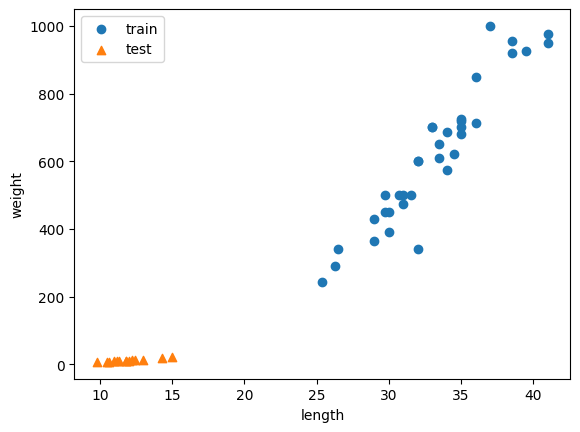

In [37]:
import matplotlib.pyplot as plt
# 훈련 세트의 산점도
plt.scatter([l for l, w in train_input], [w for l, w in train_input], marker='o', label='train')
# 테스트 세트의 산점도
plt.scatter([l for l, w in test_input], [w for l, w in test_input], marker='^', label='test')
# x축 레이블
plt.xlabel('length')
# y축 레이블
plt.ylabel('weight')
# 범례 표시
plt.legend()
plt.show()

산점도를 보아도 샘플링 편향이 일어난 것을 볼 수 있다.

배열 작업을 편하게 진행하기 위해, Numpy를 도입하겠다.
넘파이(Numpy)는 파이썬의 배열 라이브러리이다.
#
[공식 문서](https://numpy.org/doc/)

고차원 배열 작성하기, 배열 정리 등 많은 기능을 제공한다.

>n차원 배열은 말 그래도 '차원'으로 보면 편한다.
>1차원 배열은 축이 하나인 직선,
>2차원 배열은 평면,
>3차원 배열은 입체 평면이다.

넘파이를 사용하기 위해서는 우선 설치가 필요하다.
```bash
pip install numpy
```

이후, 다음과 같이 불러온다.
```python
import numpy as np
```
>numpy의 약어는 `np`이다

파이썬에서 제공하는 일반 리스트(`array`)와, numpy의 리스트(배열)은 다른 자료형으로 취급된다.
또한, 모든 원소가 동일한 타입이어야 한다.

파이썬 리스트를 다음과 같이 numpy 배열로 변환한다.

In [38]:
import numpy as np

# 파이썬 리스트를 numpy 배열로 변환
input_arr = np.array(fish_data)
target_arr = np.array(fish_target)

# input_arr와 target_arr의 타입 확인
print("# 타입 확인")
print(f"input_arr: {type(input_arr)}\ntarget_arr: {type(target_arr)}")

# input_arr와 target_arr 출력
print("# input_arr와 target_arr 출력")
print("input_arr:")
print(input_arr)
print("target_arr:")
print(target_arr)

# 타입 확인
input_arr: <class 'numpy.ndarray'>
target_arr: <class 'numpy.ndarray'>
# input_arr와 target_arr 출력
input_arr:
[[  25.4  242. ]
 [  26.3  290. ]
 [  26.5  340. ]
 [  29.   363. ]
 [  29.   430. ]
 [  29.7  450. ]
 [  29.7  500. ]
 [  30.   390. ]
 [  30.   450. ]
 [  30.7  500. ]
 [  31.   475. ]
 [  31.   500. ]
 [  31.5  500. ]
 [  32.   340. ]
 [  32.   600. ]
 [  32.   600. ]
 [  33.   700. ]
 [  33.   700. ]
 [  33.5  610. ]
 [  33.5  650. ]
 [  34.   575. ]
 [  34.   685. ]
 [  34.5  620. ]
 [  35.   680. ]
 [  35.   700. ]
 [  35.   725. ]
 [  35.   720. ]
 [  36.   714. ]
 [  36.   850. ]
 [  37.  1000. ]
 [  38.5  920. ]
 [  38.5  955. ]
 [  39.5  925. ]
 [  41.   975. ]
 [  41.   950. ]
 [   9.8    6.7]
 [  10.5    7.5]
 [  10.6    7. ]
 [  11.     9.7]
 [  11.2    9.8]
 [  11.3    8.7]
 [  11.8   10. ]
 [  11.8    9.9]
 [  12.     9.8]
 [  12.2   12.2]
 [  12.4   13.4]
 [  13.    12.2]
 [  14.3   19.7]
 [  15.    19.9]]
target_arr:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 

numpy는 배열의 행과 열을 정리하여 출력한다.

이외에도 numpy는 배열의 구조를 확인할 수 있는 `shape` 속성이 존재한다.

`(샘플 수, 특성 수)` 형태로 배열의 정보가 출력된다.

In [39]:
print(input_arr.shape) # (샘플 수, 특성 수)

(49, 2)


이제, `input_arr`와 `target_arr`를 섞어 샘플링 편향이 일어나지 않도록 해야 한다.

**여기서 주의할 점은, `input_arr`와 `target_arr`는 같이 섞여야 한다는 점이다.**
`target_arr`는 `input_arr`의 종류를 알려주는데, 이것이 변경되어서는 안된다.

`target_arr`와 `input_arr`값이 공통으로 참조하는 인덱스 위치가 저장된 배열이 필요하다.

현재 기준으로 하는 책에서는 numpy에서 `arange()` 메서드를 사용하라는 점이다.
>`arange()`는 0에서 `매개변수로 받은 수-1`의 값까지 숫자를 포함한 배열을 선언한다.

In [40]:
np.random.seed(42)  # 랜덤 시드 설정
# 0에서 input_arr의 길이-1까지의 숫자를 포함하는 배열 생성
index = np.arange(len(input_arr))
# index 배열을 섞기
np.random.shuffle(index)

print(index)  # 섞인 인덱스 배열 출력

[13 45 47 44 17 27 26 25 31 19 12  4 34  8  3  6 40 41 46 15  9 16 24 33
 30  0 43 32  5 29 11 36  1 21  2 37 35 23 39 10 22 18 48 20  7 42 14 28
 38]


배열이 출력되었다. 이제 해당하는 인덱스를 선택하여, 따로 저장하자.

이를 위해서는 numpy에서 제공하는 배열 인덱싱(array indexing)를 사용해야 한다.
1개의 인덱스가 아닌 여러 개의 인덱스로 배열의 element를 선택할 수 있다.

In [41]:
print(input_arr[[1, 3]])

[[ 26.3 290. ]
 [ 29.  363. ]]


`input_arr`의 2 번째 요소와 4번째 요소가 선택되어 출력되었다.

이를 이용해 `index` 배열의 값을 참조하여, 인덱스를 선택해 공통된 `input_arr`와 `target_arr`를 지정할 수 있게 한다

In [42]:
train_input = input_arr[index[:35]]
train_target = target_arr[index[:35]]
# 34개의 훈련 데이터와 14개의 테스트 데이터로 나누기

검증해보자.
`index` 배열의 첫 번 째 값은 `13`이었다.
`input_arr`를 사용한다면, `train_input`의 첫 번째 값은 `input_arr`의 13번째(14)번째 샘플이어야 한다.

In [43]:
print(train_input[0], input_arr[13])

[ 32. 340.] [ 32. 340.]


일치한다.
이번에는 나머지 데이터들을 테스트 세트로 추출하겠다.

In [44]:
test_input = input_arr[index[35:]]
test_target = target_arr[index[35:]]

이제 모든 데이터가 준비되었다.
이 데이터들을 시각화하여 표현해보자.

> 시각화할 때, 2차원 배열 내에서 인덱스를 슬라이싱할 때는 다음과 같이 `[:,index]` 형태로 사용한다.

In [45]:
print(train_input[:,0], train_input[:,1])

[32.  12.4 14.3 12.2 33.  36.  35.  35.  38.5 33.5 31.5 29.  41.  30.
 29.  29.7 11.3 11.8 13.  32.  30.7 33.  35.  41.  38.5 25.4 12.  39.5
 29.7 37.  31.  10.5 26.3 34.  26.5] [ 340.    13.4   19.7   12.2  700.   714.   720.   725.   955.   650.
  500.   430.   950.   450.   363.   500.     8.7   10.    12.2  600.
  500.   700.   700.   975.   920.   242.     9.8  925.   450.  1000.
  500.     7.5  290.   685.   340. ]


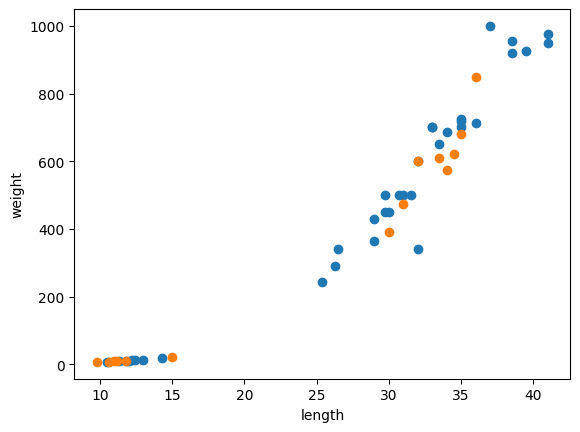

In [46]:
plt.scatter(train_input[:,0], train_input[:,1])
plt.scatter(test_input[:,0], test_input[:,1])
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

이제 데이터 확인까지 마쳤으니, 데이터를 토대로 모델을 훈련시키자.

In [47]:
kn.fit(train_input, train_target)
kn.score(test_input, test_target)

1.0

`1.0`의 스코어로 모든 생선을 맞추었다.

`predict()`를 사용하여 모델을 사용해보자.

In [ ]:
kn.predict(test_input)

[0 0 1 0 1 1 1 0 1 1 0 1 1 0]


In [50]:
print(test_target)

[0 0 1 0 1 1 1 0 1 1 0 1 1 0]


검사한 값과 출력된 타겟 데이터가 일치한다.

# 정리
이제 훈련한 데이터와 테스트한 데이터가 일치하지 않으니 올바르게 모델이 평가되었다.

이 파일에서는 넘파이(numpy) 라는 라이브러리를 활용해 샘플 데이터와 타깃 데이터의 인덱스를 공통하게 유지해 입력 데이터와 테스트 데이터를 구분했다.